# Day 9: Normal Distribution, Sampling & Sampling Techniques

## Learning Objectives
- Understand normal distribution and its characteristics.
- Apply the Empirical Rule (68–95–99.7 rule).
- Calculate and interpret Z-scores.
- Understand population and sample.
- Explore simple random, systematic, stratified, and cluster sampling.
- Apply sampling concepts using Python.

**Libraries:** NumPy, Pandas, Matplotlib, Seaborn, SciPy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm

sns.set_theme(style="whitegrid")

## 1. Understanding Normal Distribution

A normal distribution is a continuous probability distribution that is:
- Bell-shaped.
- Symmetric around its mean.
- Characterized by its mean and standard deviation.
- Mean = Median = Mode (for a perfect normal distribution).

The total area under the curve is equal to 1 (100% probability).

In [2]:
np.random.seed(42)

data = np.random.normal(
    loc=100,
    scale=15,
    size=1000
)

df = pd.DataFrame({
    "value": data
})

df.head()

,value
0,107.450712
1,97.926035
2,109.715328
3,122.845448
4,96.487699


In [3]:
df["value"].describe()

,value
count,1000.000000
mean,100.289981
std,14.688239
min,51.380990
25%,90.286145
50%,100.379509
75%,109.719158
max,157.790972


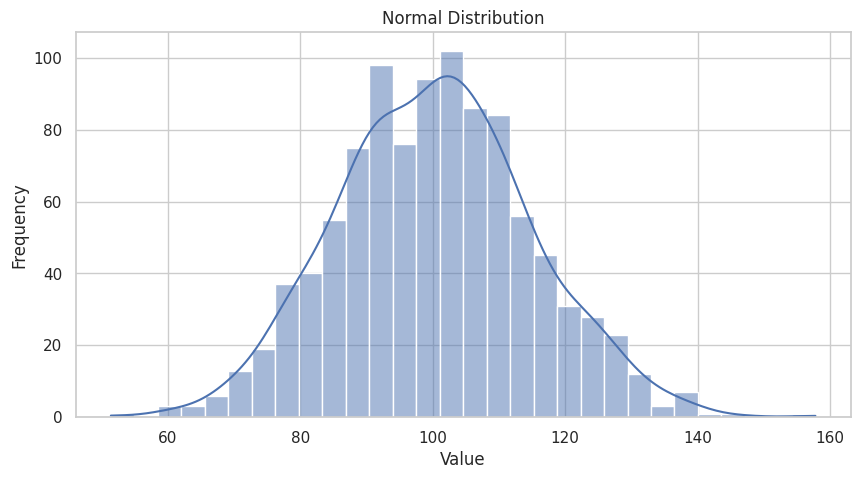

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["value"],
    bins=30,
    kde=True
)

plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.show()

## 2. The Empirical Rule (68–95–99.7 Rule)

For a perfectly normal distribution:

- Approximately 68% of observations fall within 1 standard deviation of the mean.
- Approximately 95% fall within 2 standard deviations.
- Approximately 99.7% fall within 3 standard deviations.

This rule helps us understand how values are distributed around the mean.

In [5]:
mean = df["value"].mean()
std = df["value"].std()

ranges = {
    "Within 1 SD": (
        mean - std,
        mean + std
    ),
    "Within 2 SD": (
        mean - 2 * std,
        mean + 2 * std
    ),
    "Within 3 SD": (
        mean - 3 * std,
        mean + 3 * std
    )
}

for label, (lower, upper) in ranges.items():

    percentage = (
        df["value"].between(lower, upper).mean() * 100
    )

    print(
        f"{label}: {percentage:.2f}% "
        f"({lower:.2f} to {upper:.2f})"
    )

Within 1 SD: 68.60% (85.60 to 114.98)
Within 2 SD: 95.60% (70.91 to 129.67)
Within 3 SD: 99.70% (56.23 to 144.35)


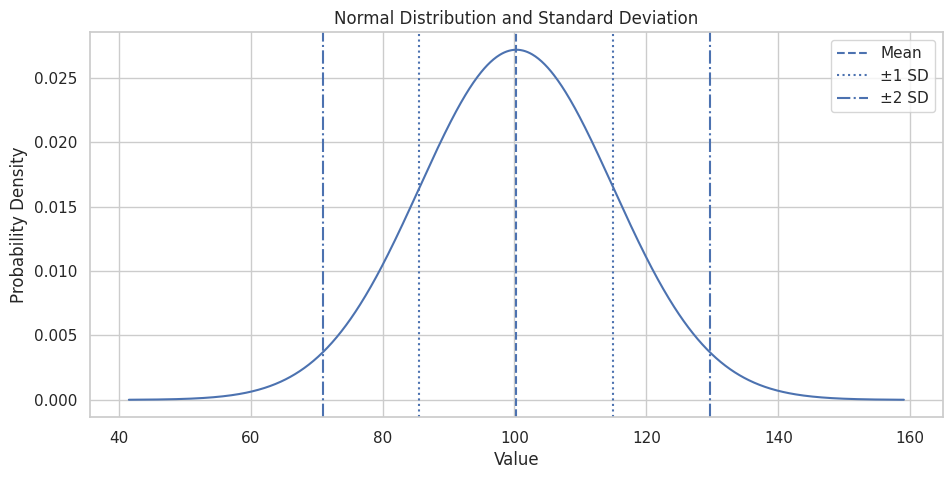

In [6]:
x = np.linspace(
    mean - 4 * std,
    mean + 4 * std,
    1000
)

y = norm.pdf(
    x,
    loc=mean,
    scale=std
)

plt.figure(figsize=(11, 5))

plt.plot(x, y)

plt.axvline(mean, linestyle="--", label="Mean")

plt.axvline(mean - std, linestyle=":")
plt.axvline(mean + std, linestyle=":", label="±1 SD")

plt.axvline(mean - 2 * std, linestyle="-.")
plt.axvline(mean + 2 * std, linestyle="-.", label="±2 SD")

plt.title("Normal Distribution and Standard Deviation")
plt.xlabel("Value")
plt.ylabel("Probability Density")
plt.legend()

plt.show()

## 3. Z-Score

A Z-score tells us how many standard deviations an observation is away from the mean.

Formula:

Z = (X - Mean) / Standard Deviation

Interpretation:
- Z = 0: Value is equal to the mean.
- Z = 1: Value is 1 standard deviation above the mean.
- Z = -1: Value is 1 standard deviation below the mean.
- A large absolute Z-score indicates a value far from the mean.

Z-scores are useful for comparing values measured on different scales.

In [7]:
df["z_score"] = (
    df["value"] - mean
) / std

df.head()

,value,z_score
0,107.450712,0.487515
1,97.926035,-0.160941
2,109.715328,0.641693
3,122.845448,1.535614
4,96.487699,-0.258866


In [8]:
df["is_extreme"] = df["z_score"].abs() > 3

df["is_extreme"].value_counts()

,count
is_extreme,
False,997
True,3


## 4. Population vs Sample

**Population:** The complete group of individuals or observations we want to study.

**Sample:** A smaller subset selected from the population.

Example:
- Population: All customers of an e-commerce company.
- Sample: 500 customers selected for a customer satisfaction survey.

Why do we use samples?
- Studying the entire population can be expensive.
- It can take too much time.
- Sometimes collecting data from everyone is not possible.

A good sample should represent the population as accurately as possible.

In [9]:
np.random.seed(42)

population = pd.DataFrame({
    "customer_id": range(1, 10001),
    "age": np.random.randint(18, 65, 10000),
    "purchase_amount": np.random.normal(
        loc=2500,
        scale=700,
        size=10000
    )
})

population.head()

,customer_id,age,purchase_amount
0,1,56,1397.991856
1,2,46,1799.578333
2,3,32,2372.854147
3,4,60,2904.811597
4,5,25,1895.151034


In [10]:
random_sample = population.sample(
    n=500,
    random_state=42
)

print("Population size:", len(population))
print("Sample size:", len(random_sample))

random_sample.head()

Population size: 10000
Sample size: 500


,customer_id,age,purchase_amount
6252,6253,52,2809.288381
4684,4685,40,2016.565753
1731,1732,52,2928.203702
4742,4743,20,3221.656298
4521,4522,18,3441.856826


In [11]:
comparison = pd.DataFrame({
    "Population Mean": population[
        ["age", "purchase_amount"]
    ].mean(),

    "Sample Mean": random_sample[
        ["age", "purchase_amount"]
    ].mean()
})

comparison

,Population Mean,Sample Mean
age,41.054000,42.2140
purchase_amount,2500.203989,2474.6683


## 5. Sampling Techniques

### 1. Simple Random Sampling
Every population member has an equal chance of being selected.

### 2. Systematic Sampling
Select every kth observation after choosing a starting point.

### 3. Stratified Sampling
Divide the population into meaningful groups (strata) and select samples from each group.

### 4. Cluster Sampling
Divide the population into clusters, randomly select some clusters, and study the members of the selected clusters.

The sampling technique should be selected according to the business problem and population structure.

In [12]:
k = 10

systematic_sample = population.iloc[::k]

print("Systematic sample size:", len(systematic_sample))

systematic_sample.head()

Systematic sample size: 1000


,customer_id,age,purchase_amount
0,1,56,1397.991856
10,11,28,3175.485685
20,21,47,3583.590938
30,31,59,2007.138655
40,41,26,1653.498511


In [13]:
stratified_sample = (
    population
    .groupby(
        pd.cut(
            population["age"],
            bins=[17, 30, 45, 65],
            labels=["18-30", "31-45", "46-65"]
        ),
        observed=True
    )
    .sample(
        n=50,
        random_state=42
    )
)

print("Stratified sample size:", len(stratified_sample))

stratified_sample.head()

Stratified sample size: 150


,customer_id,age,purchase_amount
3932,3933,19,2624.468225
1546,1547,18,3353.063861
9253,9254,27,2552.169931
8476,8477,30,2450.698141
4650,4651,21,3276.861355


In [14]:
np.random.seed(42)

population["cluster"] = np.random.randint(
    1,
    21,
    size=len(population)
)

selected_clusters = np.random.choice(
    population["cluster"].unique(),
    size=4,
    replace=False
)

cluster_sample = population[
    population["cluster"].isin(selected_clusters)
]

print("Selected clusters:", selected_clusters)
print("Cluster sample size:", len(cluster_sample))

cluster_sample.head()

Selected clusters: [ 3 19 15  8]
Cluster sample size: 2024


,customer_id,age,purchase_amount,cluster
2,3,32,2372.854147,15
4,5,25,1895.151034,8
6,7,56,1648.374938,19
10,11,28,3175.485685,8
11,12,41,3103.756970,3


## 6. Sampling Techniques: Quick Comparison

| Technique | How It Works | Example |
|---|---|---|
| Simple Random | Randomly select individuals | Randomly select 500 customers |
| Systematic | Select every kth observation | Select every 10th customer |
| Stratified | Sample from every group | Select customers from each age group |
| Cluster | Randomly select entire groups | Select 4 store locations and survey their customers |

**Important:** A larger sample does not automatically guarantee a representative sample. The sampling method and possible bias also matter.

## 7. Business Applications

### E-commerce
Use customer samples to estimate average spending and understand customer satisfaction.

### Banking
Use random samples of loan applications for quality checks and risk analysis.

### Marketing
Use stratified sampling to ensure different customer segments are represented in a survey.

### Retail
Use systematic sampling to inspect products or transactions at regular intervals.

### Operations
Use normal distribution concepts to understand delivery times and identify unusually delayed deliveries.

**Important:** Real business data is not always normally distributed. Always inspect the data before applying normal-distribution assumptions.

## 8. Interview Questions and Answers

**Q1. What is a normal distribution?**  
A continuous, symmetric, bell-shaped probability distribution.

**Q2. What are the mean, median, and mode in a perfect normal distribution?**  
They are equal.

**Q3. What is the Empirical Rule?**  
It states that approximately 68%, 95%, and 99.7% of observations lie within 1, 2, and 3 standard deviations of the mean.

**Q4. What is a Z-score?**  
It measures how many standard deviations a value is away from the mean.

**Q5. What is the difference between population and sample?**  
Population includes the entire group, while a sample is a subset of that group.

**Q6. Why do analysts use sampling?**  
To save time and cost when studying the entire population is difficult.

**Q7. What is simple random sampling?**  
A method where each population member has an equal chance of selection.

**Q8. What is stratified sampling?**  
A method where the population is divided into groups and samples are selected from each group.

**Q9. What is the difference between stratified and cluster sampling?**  
Stratified sampling selects members from every group. Cluster sampling selects some entire groups.

**Q10. Does a larger sample always guarantee better results?**  
No. A representative sample and an appropriate sampling method are also important.

## 9. Practice Tasks

1. Generate 5,000 normally distributed values with mean 50 and standard deviation 10.
2. Plot a histogram with a KDE curve.
3. Calculate the mean, median, and standard deviation.
4. Calculate Z-scores and identify observations with an absolute Z-score greater than 2.
5. Create a random sample of 200 observations and compare its mean with the population mean.
6. Apply systematic sampling with k = 20.
7. Create age-based strata and select 30 observations from each group.
8. Explain the difference between stratified and cluster sampling using a business example.

Try to complete these tasks independently.

## Day 9 — Key Takeaways

- Normal distribution is symmetric and bell-shaped.
- The Empirical Rule describes how observations spread around the mean.
- Z-scores help identify how far values are from the mean.
- Population represents the complete group; a sample represents a subset.
- Simple random, systematic, stratified, and cluster sampling are important sampling techniques.
- Representative sampling is essential for reliable business analysis.

### Next Topic: Day 10
Sampling Distribution, Central Limit Theorem (CLT), Standard Error & Confidence Intervals.